# Handwritten Digit Classification Using CNN

This notebook trains a CNN model on the MNIST handwritten digit dataset.


HANDWRITTEN DIGIT CLASSIFICATION USING CNN

MNIST dataset already exists.
Dataset location: C:\study\InternShips\AI\task 2\dataset\mnist.npz

Loading MNIST dataset...


Training images: (60000, 28, 28)
Testing images : (10000, 28, 28)


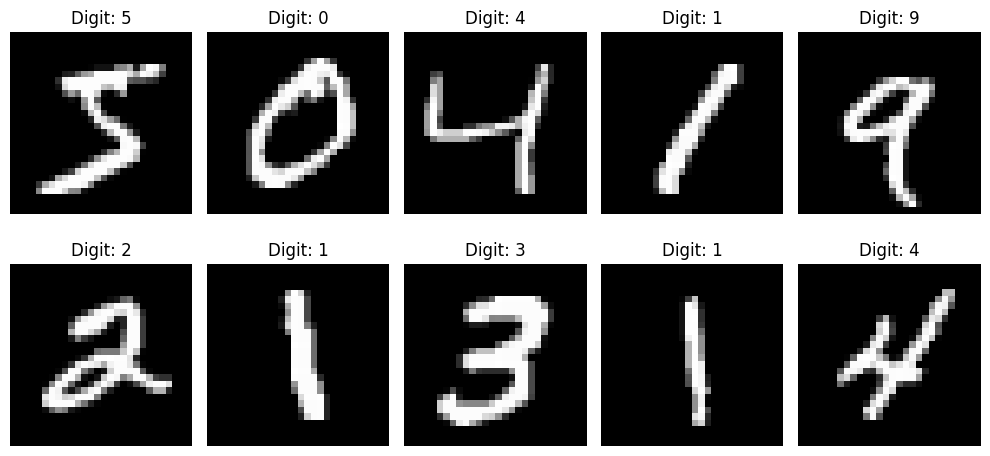


Preprocessing images...


Training shape after preprocessing: (60000, 28, 28, 1)
Testing shape after preprocessing : (10000, 28, 28, 1)

Building CNN model...


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

... (1,482 outputs left out)

843/844 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9861 - loss: 0.0473

844/844 ━━━━━━━━━━━━━━━━━━━━ 20s 24ms/step - accuracy: 0.9863 - loss: 0.0458 - val_accuracy: 0.9910 - val_loss: 0.0339



Evaluating model...



Test Loss     : 0.032721031457185745
Test Accuracy : 0.9887999892234802


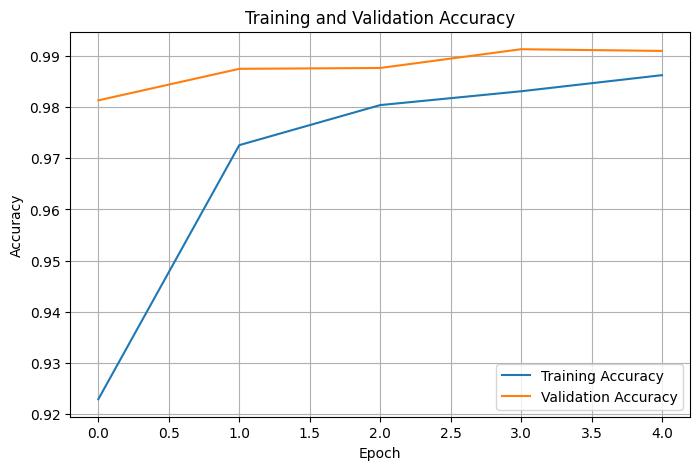

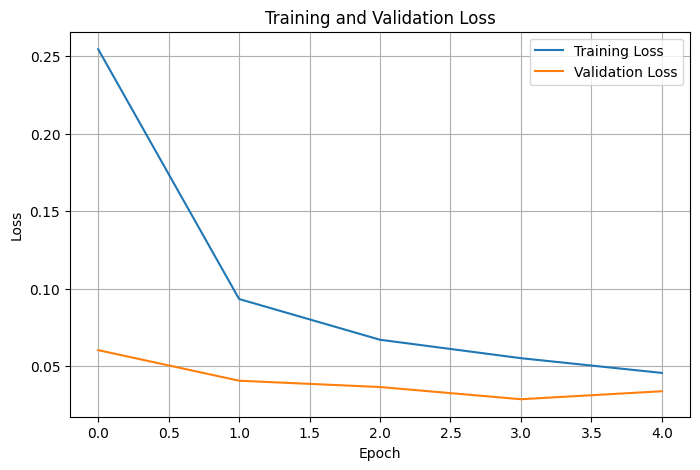


Generating predictions...



CLASSIFICATION RESULTS

Accuracy: 0.9888

Classification Report:

              precision    recall  f1-score   support

           0       0.98      1.00      0.99       980
           1       0.99      1.00      0.99      1135
           2       0.99      0.99      0.99      1032
           3       0.98      1.00      0.99      1010
           4       0.99      0.99      0.99       982
           5       0.99      0.99      0.99       892
           6       1.00      0.99      0.99       958
           7       0.99      0.98      0.98      1028
           8       1.00      0.98      0.99       974
           9       0.99      0.98      0.98      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



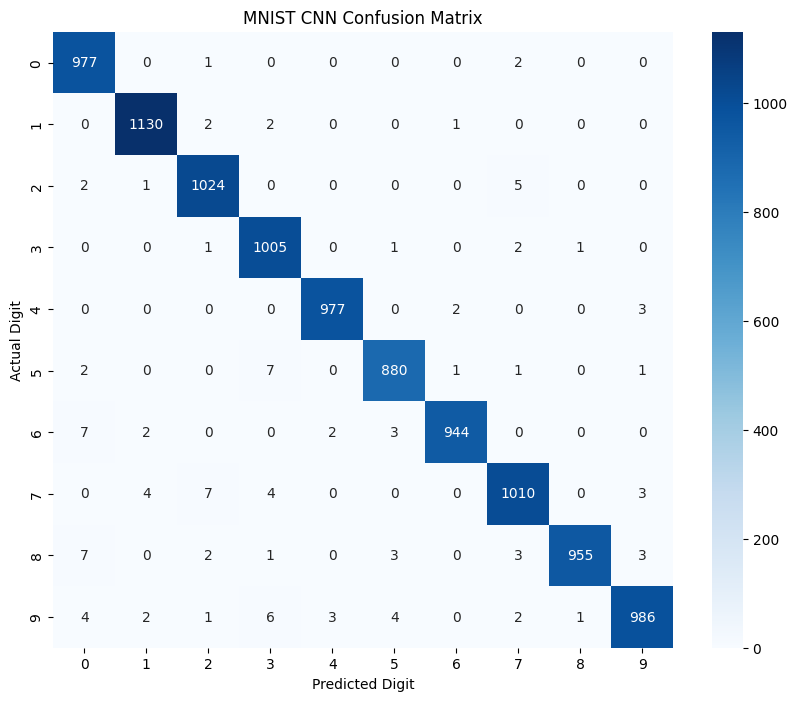

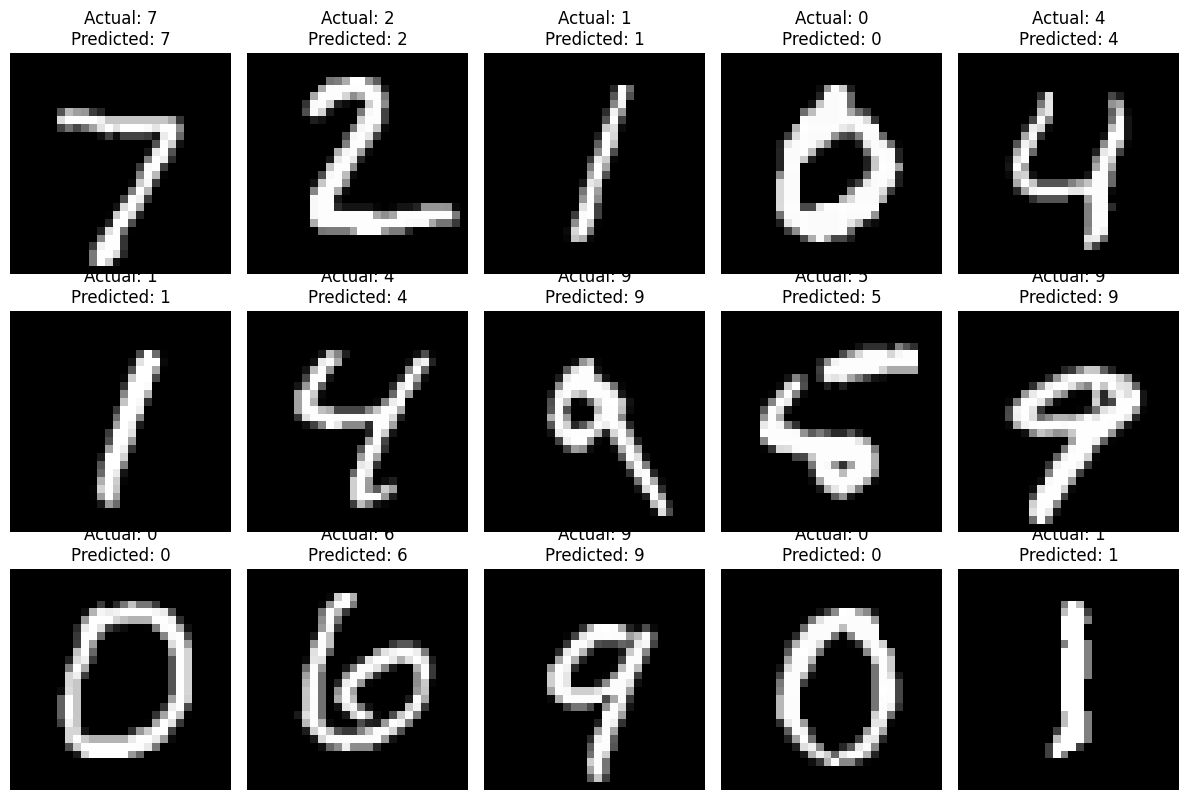


Model saved as: C:\study\InternShips\AI\task 2\mnist_digit_model.keras

SAMPLE PREDICTION
Actual digit    : 7
Predicted digit : 7

TASK 2 COMPLETED

Project files generated:
1. dataset/mnist.npz
2. sample_digits.png
3. accuracy_curve.png
4. loss_curve.png
5. confusion_matrix.png
6. sample_predictions.png
7. mnist_digit_model.keras

Final Test Accuracy: 0.9887999892234802

The CNN successfully classifies handwritten digits from 0 to 9.


In [1]:
import os
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score


# ============================================================
# 1. Project Information
# ============================================================

print("=" * 60)
print("HANDWRITTEN DIGIT CLASSIFICATION USING CNN")
print("=" * 60)


# ============================================================
# 2. Create Dataset Folder
# ============================================================

BASE_DIR = os.getcwd()
DATASET_DIR = os.path.join(BASE_DIR, "dataset")

os.makedirs(DATASET_DIR, exist_ok=True)

DATASET_PATH = os.path.join(DATASET_DIR, "mnist.npz")


# ============================================================
# 3. Download MNIST Dataset into Project Folder
# ============================================================

DATASET_URL = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"

if not os.path.exists(DATASET_PATH):

    print("\nMNIST dataset not found.")
    print("Downloading MNIST dataset...")

    urllib.request.urlretrieve(
        DATASET_URL,
        DATASET_PATH
    )

    print("Dataset downloaded successfully.")
    print("Dataset location:", DATASET_PATH)

else:

    print("\nMNIST dataset already exists.")
    print("Dataset location:", DATASET_PATH)


# ============================================================
# 4. Load Dataset from Local Project Folder
# ============================================================

print("\nLoading MNIST dataset...")

with np.load(DATASET_PATH) as data:

    x_train = data["x_train"]
    y_train = data["y_train"]
    x_test = data["x_test"]
    y_test = data["y_test"]


print("Training images:", x_train.shape)
print("Testing images :", x_test.shape)


# ============================================================
# 5. Display Sample Images
# ============================================================

plt.figure(figsize=(10, 5))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(
        x_train[i],
        cmap="gray"
    )

    plt.title(f"Digit: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()

plt.savefig(
    "sample_digits.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 6. Preprocessing
# ============================================================

print("\nPreprocessing images...")

# Convert pixel values from 0-255 to 0-1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Add channel dimension
# (60000, 28, 28) → (60000, 28, 28, 1)

x_train = np.expand_dims(
    x_train,
    axis=-1
)

x_test = np.expand_dims(
    x_test,
    axis=-1
)

print(
    "Training shape after preprocessing:",
    x_train.shape
)

print(
    "Testing shape after preprocessing :",
    x_test.shape
)


# ============================================================
# 7. Build CNN Model
# ============================================================

print("\nBuilding CNN model...")

model = models.Sequential([

    layers.Input(
        shape=(28, 28, 1)
    ),

    # First convolution block
    layers.Conv2D(
        32,
        (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    # Second convolution block
    layers.Conv2D(
        64,
        (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    # Flatten feature maps
    layers.Flatten(),

    # Fully connected layer
    layers.Dense(
        128,
        activation="relu"
    ),

    # Reduce overfitting
    layers.Dropout(0.5),

    # Output layer: digits 0-9
    layers.Dense(
        10,
        activation="softmax"
    )
])


# ============================================================
# 8. Display Model Architecture
# ============================================================

model.summary()


# ============================================================
# 9. Compile Model
# ============================================================

model.compile(

    optimizer="adam",

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)


# ============================================================
# 10. Train CNN
# ============================================================

print("\nTraining CNN model...")

history = model.fit(

    x_train,

    y_train,

    epochs=5,

    batch_size=64,

    validation_split=0.1,

    verbose=1
)


# ============================================================
# 11. Evaluate Model
# ============================================================

print("\nEvaluating model...")

test_loss, test_accuracy = model.evaluate(

    x_test,

    y_test,

    verbose=0
)


print("\nTest Loss     :", test_loss)

print(
    "Test Accuracy :",
    test_accuracy
)


# ============================================================
# 12. Accuracy Curve
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title(
    "Training and Validation Accuracy"
)

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.grid(True)

plt.savefig(
    "accuracy_curve.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 13. Loss Curve
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title(
    "Training and Validation Loss"
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.grid(True)

plt.savefig(
    "loss_curve.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 14. Generate Predictions
# ============================================================

print("\nGenerating predictions...")

y_probability = model.predict(

    x_test,

    verbose=0
)


y_pred = np.argmax(

    y_probability,

    axis=1
)


# ============================================================
# 15. Classification Metrics
# ============================================================

accuracy = accuracy_score(

    y_test,

    y_pred
)


print("\n" + "=" * 60)

print("CLASSIFICATION RESULTS")

print("=" * 60)


print(
    "\nAccuracy:",
    accuracy
)


print(
    "\nClassification Report:\n"
)


print(
    classification_report(
        y_test,
        y_pred
    )
)


# ============================================================
# 16. Confusion Matrix
# ============================================================

cm = confusion_matrix(

    y_test,

    y_pred
)


plt.figure(figsize=(10, 8))


sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    cmap="Blues"
)


plt.title(
    "MNIST CNN Confusion Matrix"
)

plt.xlabel(
    "Predicted Digit"
)

plt.ylabel(
    "Actual Digit"
)


plt.savefig(

    "confusion_matrix.png",

    dpi=150,

    bbox_inches="tight"
)


plt.show()


# ============================================================
# 17. Sample Predictions
# ============================================================

plt.figure(figsize=(12, 8))


for i in range(15):

    plt.subplot(
        3,
        5,
        i + 1
    )


    plt.imshow(

        x_test[i].reshape(28, 28),

        cmap="gray"
    )


    plt.title(

        f"Actual: {y_test[i]}\n"
        f"Predicted: {y_pred[i]}"
    )


    plt.axis("off")


plt.tight_layout()


plt.savefig(

    "sample_predictions.png",

    dpi=150,

    bbox_inches="tight"
)


plt.show()


# ============================================================
# 18. Save Trained Model
# ============================================================

MODEL_PATH = os.path.join(

    BASE_DIR,

    "mnist_digit_model.keras"
)


model.save(

    MODEL_PATH
)


print(
    "\nModel saved as:",
    MODEL_PATH
)


# ============================================================
# 19. Test One Sample
# ============================================================

sample_index = 0


sample_image = x_test[sample_index]


sample_prediction = model.predict(

    np.expand_dims(
        sample_image,
        axis=0
    ),

    verbose=0
)


predicted_digit = np.argmax(

    sample_prediction
)


print("\n" + "=" * 60)

print("SAMPLE PREDICTION")

print("=" * 60)


print(
    "Actual digit    :",
    y_test[sample_index]
)


print(
    "Predicted digit :",
    predicted_digit
)


# ============================================================
# 20. Final Summary
# ============================================================

print("\n" + "=" * 60)

print("TASK 2 COMPLETED")

print("=" * 60)


print("\nProject files generated:")

print("1. dataset/mnist.npz")

print("2. sample_digits.png")

print("3. accuracy_curve.png")

print("4. loss_curve.png")

print("5. confusion_matrix.png")

print("6. sample_predictions.png")

print("7. mnist_digit_model.keras")


print(
    "\nFinal Test Accuracy:",
    test_accuracy
)


print(
    "\nThe CNN successfully classifies "
    "handwritten digits from 0 to 9."
)